# Phase 05 — Python Exploratory Data Analysis & Segmentation

## Project: Product Funnel and Conversion Drop-off Analysis

### Objective
Analyze e-commerce customer behavior using Python and pandas to investigate conversion patterns, funnel drop-offs, and differences across meaningful customer and product segments.

### Funnel Definition
Product View → Add to Cart → Purchase

Primary analysis unit: unique customer-session-product journey.

Journey key: `user_id + user_session + product_id`

Valid event sequence: `view_time < cart_time < purchase_time`

### Analysis Goals
1. Explore the cleaned e-commerce dataset.
2. Validate key data characteristics and funnel baselines.
3. Investigate customer and product behavior.
4. Compare conversion and drop-off across available segments.
5. Create meaningful Python visualizations.
6. Document business insights, assumptions, and limitations.

### Tools
Python 3.13, pandas, Jupyter Notebook, PostgreSQL 18, and Git.

### Methodology
Reuse existing cleaned data and verified funnel definitions. Do not mix customer-level and journey-level metrics. Investigate discrepancies rather than forcing results to match established baselines.

In [1]:

# Step 05.04 — Verify Python EDA Libraries

import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns

print("========== PYTHON EDA ENVIRONMENT ==========")
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("============================================")
print("All EDA libraries imported successfully!")


========== PYTHON EDA ENVIRONMENT ==========
Python: 3.13.15
pandas: 3.1.0
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
All EDA libraries imported successfully!


In [2]:

# Step 05.05 — Locate Existing Cleaned Dataset

from pathlib import Path

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

clean_dir = project_root / "data" / "clean"

print("========== CLEANED DATASET FILES ==========")
print("Project directory:", project_root)
print("Clean data directory:", clean_dir)

if clean_dir.exists():
    files = sorted(clean_dir.iterdir())

    for file in files:
        if file.is_file():
            print(f"{file.name} | {file.stat().st_size / (1024**2):.2f} MB")

    if not files:
        print("Clean data directory is empty.")
else:
    print("Clean data directory not found.")


========== CLEANED DATASET FILES ==========
Project directory: C:\Users\kunal\OneDrive\Desktop\product-funnel-analysis
Clean data directory: C:\Users\kunal\OneDrive\Desktop\product-funnel-analysis\data\clean
october_customer_sample_clean.csv | 112.37 MB


In [3]:

# Step 05.06 — Load Cleaned Dataset

clean_file = clean_dir / "october_customer_sample_clean.csv"

df = pd.read_csv(clean_file)

print("========== CLEANED DATASET LOADED ==========")
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
print("============================================")

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


========== CLEANED DATASET LOADED ==========
Rows: 849,220
Columns: 9
Memory usage: 295.43 MB

Column names:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']

First 5 rows:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:56+0000,view,4804295,2053013554658804075,electronics.audio.headphone,xiaomi,23.13,541366014,6d8ce6fb-2953-4e95-96fe-b40f1ec50ba8
1,2019-10-01 00:03:35+0000,view,1005115,2053013555631882655,electronics.smartphone,apple,975.57,519829701,c3012f56-70f3-4198-960d-5f14467c0a53
2,2019-10-01 00:07:43+0000,view,15100370,2053013557024391671,Unknown,Unknown,257.15,527776076,b1185e33-79ce-4fcb-b85a-d06aeb87beee
3,2019-10-01 00:08:33+0000,view,15100350,2053013557024391671,Unknown,Unknown,321.73,527776076,b1185e33-79ce-4fcb-b85a-d06aeb87beee
4,2019-10-01 00:09:19+0000,view,15100100,2053013557024391671,Unknown,Unknown,437.33,527776076,b1185e33-79ce-4fcb-b85a-d06aeb87beee


In [4]:

# Step 05.07 — Inspect Dataset Structure and Data Types

print("========== DATASET STRUCTURE ==========")

df.info()

print("\n========== COLUMN DATA TYPES ==========")
print(df.dtypes)

print("\n========== MISSING VALUES ==========")
print(df.isna().sum())

print("\n========== DUPLICATE ROWS ==========")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")


========== DATASET STRUCTURE ==========
<class 'pandas.DataFrame'>
RangeIndex: 849220 entries, 0 to 849219
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     849220 non-null  str    
 1   event_type     849220 non-null  str    
 2   product_id     849220 non-null  int64  
 3   category_id    849220 non-null  int64  
 4   category_code  849220 non-null  str    
 5   brand          849220 non-null  str    
 6   price          849220 non-null  float64
 7   user_id        849220 non-null  int64  
 8   user_session   849220 non-null  str    
dtypes: float64(1), int64(3), str(5)
memory usage: 58.3 MB

========== COLUMN DATA TYPES ==========
event_time           str
event_type           str
product_id         int64
category_id        int64
category_code        str
brand                str
price            float64
user_id            int64
user_session         str
dtype: object

========== MISSING VALUES 

In [5]:

# Step 05.08 — Investigate Exact Duplicate Events

duplicate_mask = df.duplicated(keep="first")

duplicate_events = df.loc[duplicate_mask]

print("========== DUPLICATE EVENT ANALYSIS ==========")

print(f"Total rows: {len(df):,}")
print(f"Exact duplicate rows: {duplicate_mask.sum():,}")

print("\nDuplicate rows by event type:")
print(duplicate_events["event_type"].value_counts())

print("\nDuplicate percentage:")
print(f"{duplicate_mask.mean() * 100:.4f}%")

print("\nSample duplicate rows:")
display(duplicate_events.head())


========== DUPLICATE EVENT ANALYSIS ==========
Total rows: 849,220
Exact duplicate rows: 600

Duplicate rows by event type:
event_type
cart        564
view         35
purchase      1
Name: count, dtype: int64

Duplicate percentage:
0.0707%

Sample duplicate rows:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
31349,2019-10-02 07:28:47+0000,cart,1004874,2053013555631882655,electronics.smartphone,samsung,383.51,542837325,e864be69-e104-4b74-93d1-1655795244ff
34901,2019-10-02 10:09:03+0000,cart,1004229,2053013555631882655,electronics.smartphone,apple,1143.09,513643225,6185b9d1-d9ca-423d-a014-365f4fc9be97
41404,2019-10-02 15:10:41+0000,cart,1200947,2172371436436455782,electronics.tablet,samsung,115.32,554250511,6a4e7c72-5b02-46f0-9c44-b960b27ffad0
41405,2019-10-02 15:10:41+0000,cart,1200947,2172371436436455782,electronics.tablet,samsung,115.32,554250511,6a4e7c72-5b02-46f0-9c44-b960b27ffad0
41407,2019-10-02 15:10:42+0000,cart,1200947,2172371436436455782,electronics.tablet,samsung,115.32,554250511,6a4e7c72-5b02-46f0-9c44-b960b27ffad0


In [5]:

# Step 05.09 — Event Type Distribution

print("========== EVENT TYPE DISTRIBUTION ==========")

event_counts = df["event_type"].value_counts()

event_percentages = (
    df["event_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

event_summary = pd.DataFrame({
    "Event Count": event_counts,
    "Percentage (%)": event_percentages
})

display(event_summary)

print("\nTotal event records:", f"{event_counts.sum():,}")

print("\nNote: These are event-level counts, not unique funnel journeys.")


========== EVENT TYPE DISTRIBUTION ==========


,Event Count,Percentage (%)
event_type,,
view,814847,95.95
cart,18938,2.23
purchase,15435,1.82



Total event records: 849,220

Note: These are event-level counts, not unique funnel journeys.


In [7]:

# Step 05.10 — Dataset Cardinality Analysis

print("========== DATASET CARDINALITY ==========")

print(f"Unique customers: {df['user_id'].nunique():,}")
print(f"Unique products: {df['product_id'].nunique():,}")
print(f"Unique session IDs: {df['user_session'].nunique():,}")
print(f"Unique categories: {df['category_id'].nunique():,}")
print(f"Unique category codes: {df['category_code'].nunique():,}")
print(f"Unique brands: {df['brand'].nunique():,}")

print("\n========== CUSTOMER-SESSION COMBINATIONS ==========")

customer_sessions = (
    df[["user_id", "user_session"]]
    .drop_duplicates()
    .shape[0]
)

print(f"Unique customer-session pairs: {customer_sessions:,}")

print("\nNote: These are distinct entity counts, not funnel conversion metrics.")


========== DATASET CARDINALITY ==========
Unique customers: 60,939
Unique products: 66,289
Unique session IDs: 185,065
Unique categories: 605
Unique category codes: 126
Unique brands: 2,545

========== CUSTOMER-SESSION COMBINATIONS ==========
Unique customer-session pairs: 185,065

Note: These are distinct entity counts, not funnel conversion metrics.


In [6]:

# Step 05.11 — Product Price Distribution

print("========== PRODUCT PRICE ANALYSIS ==========")

print("\nPrice summary:")
print(
    df["price"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\n========== PRICE QUALITY CHECKS ==========")

print(f"Zero-price events: {(df['price'] == 0).sum():,}")
print(f"Negative-price events: {(df['price'] < 0).sum():,}")

print("\n========== PRICE BY EVENT TYPE ==========")

display(
    df.groupby("event_type")["price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("\nNote: These statistics describe event records,")
print("not unique products or completed purchases.")


========== PRODUCT PRICE ANALYSIS ==========

Price summary:
count    849220.000000
mean        288.959290
std         355.814126
min           0.000000
25%          66.670000
50%         163.360000
75%         357.540000
90%         736.030000
95%        1007.970000
99%        1734.790000
max        2574.070000
Name: price, dtype: float64

========== PRICE QUALITY CHECKS ==========
Zero-price events: 1,469
Negative-price events: 0

========== PRICE BY EVENT TYPE ==========


,count,mean,median,min,max
event_type,,,,,
cart,18938,335.01,196.40,0.00,2342.12
purchase,15435,322.59,187.89,0.92,2557.59
view,814847,287.25,161.65,0.00,2574.07



Note: These statistics describe event records,
not unique products or completed purchases.


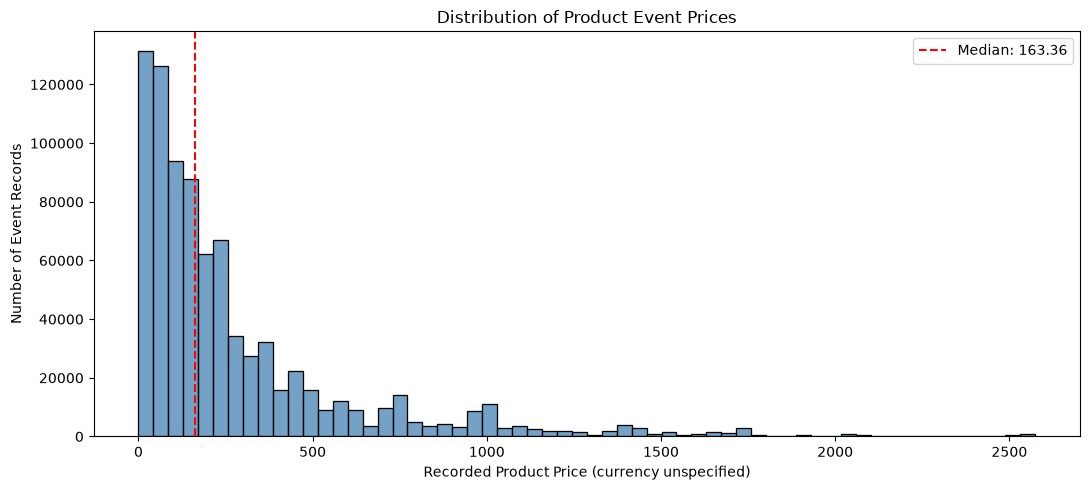

In [9]:

# Step 05.12 — Visualize Product Price Distribution

plt = matplotlib.pyplot

plt.figure(figsize=(11, 5))

sns.histplot(
    data=df,
    x="price",
    bins=60,
    color="steelblue"
)

plt.axvline(
    df["price"].median(),
    color="red",
    linestyle="--",
    label=f"Median: {df['price'].median():.2f}"
)

plt.title("Distribution of Product Event Prices")
plt.xlabel("Recorded Product Price (currency unspecified)")
plt.ylabel("Number of Event Records")
plt.legend()
plt.tight_layout()
plt.show()


In [7]:

# Step 05.13 — Top 10 Product Categories

print("========== TOP 10 PRODUCT CATEGORIES ==========")

top_categories = (
    df["category_code"]
    .value_counts()
    .head(10)
)

category_summary = pd.DataFrame({
    "Event Count": top_categories,
    "Percentage (%)": (
        top_categories / len(df) * 100
    ).round(2)
})

display(category_summary)

print("\nNote: These are event-level category counts,")
print("not unique products or journey-level conversion rates.")


========== TOP 10 PRODUCT CATEGORIES ==========


,Event Count,Percentage (%)
category_code,,
Unknown,268555,31.62
electronics.smartphone,235243,27.70
electronics.clocks,25192,2.97
electronics.audio.headphone,22942,2.70
computers.notebook,22402,2.64
electronics.video.tv,22364,2.63
appliances.kitchen.refrigerators,19093,2.25
appliances.kitchen.washer,17327,2.04
appliances.environment.vacuum,16834,1.98



Note: These are event-level category counts,
not unique products or journey-level conversion rates.


In [11]:

# Step 05.14 — Investigate Unknown Category Values

print("========== UNKNOWN CATEGORY ANALYSIS ==========")

unknown_mask = df["category_code"].eq("Unknown")

print(f"Total events: {len(df):,}")
print(f"Unknown category events: {unknown_mask.sum():,}")
print(f"Unknown category percentage: {unknown_mask.mean() * 100:.2f}%")

print("\n========== UNKNOWN CATEGORY BY EVENT TYPE ==========")

unknown_by_event = pd.crosstab(
    df["event_type"],
    unknown_mask,
    margins=False
)

unknown_by_event.columns = ["Known Category", "Unknown Category"]

unknown_by_event["Total Events"] = unknown_by_event.sum(axis=1)

unknown_by_event["Unknown (%)"] = (
    unknown_by_event["Unknown Category"]
    / unknown_by_event["Total Events"]
    * 100
).round(2)

display(unknown_by_event)

print("\nNote: Event-level analysis only.")
print("No rows have been removed or modified.")


========== UNKNOWN CATEGORY ANALYSIS ==========
Total events: 849,220
Unknown category events: 268,555
Unknown category percentage: 31.62%

========== UNKNOWN CATEGORY BY EVENT TYPE ==========


,Known Category,Unknown Category,Total Events,Unknown (%)
event_type,,,,
cart,17007,1931,18938,10.20
purchase,11908,3527,15435,22.85
view,551750,263097,814847,32.29



Note: Event-level analysis only.
No rows have been removed or modified.


In [8]:

# Step 05.15 — Top Product Brands

print("========== TOP 10 PRODUCT BRANDS ==========")

top_brands = (
    df["brand"]
    .value_counts()
    .head(10)
)

brand_summary = pd.DataFrame({
    "Event Count": top_brands,
    "Percentage (%)": (
        top_brands / len(df) * 100
    ).round(2)
})

display(brand_summary)

print("\n========== UNKNOWN BRAND ANALYSIS ==========")

unknown_brand_mask = df["brand"].eq("Unknown")

print(f"Unknown brand events: {unknown_brand_mask.sum():,}")
print(f"Unknown brand percentage: {unknown_brand_mask.mean() * 100:.2f}%")

print("\nNote: These are event-level brand frequencies,")
print("not unique-product counts or conversion rates.")


========== TOP 10 PRODUCT BRANDS ==========


,Event Count,Percentage (%)
brand,,
Unknown,121933,14.36
samsung,106483,12.54
apple,84262,9.92
xiaomi,63696,7.50
huawei,22708,2.67
lucente,12926,1.52
lg,11279,1.33
oppo,10407,1.23
bosch,10386,1.22



========== UNKNOWN BRAND ANALYSIS ==========
Unknown brand events: 121,933
Unknown brand percentage: 14.36%

Note: These are event-level brand frequencies,
not unique-product counts or conversion rates.


In [13]:

# Step 05.16 — Customer Activity Distribution

print("========== CUSTOMER ACTIVITY ANALYSIS ==========")

customer_activity = df.groupby("user_id").size()

print(f"Total unique customers: {len(customer_activity):,}")

print("\n========== EVENTS PER CUSTOMER ==========")

print(
    customer_activity.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

print("\n========== CUSTOMER ACTIVITY CHECKS ==========")

print(
    f"Customers with exactly 1 event: "
    f"{(customer_activity == 1).sum():,}"
)

print(
    f"Customers with more than 10 events: "
    f"{(customer_activity > 10).sum():,}"
)

print(
    f"Customers with more than 100 events: "
    f"{(customer_activity > 100).sum():,}"
)

print("\nNote: Activity is measured using event records.")
print("These are not unique journeys or conversion rates.")


========== CUSTOMER ACTIVITY ANALYSIS ==========
Total unique customers: 60,939

========== EVENTS PER CUSTOMER ==========
count    60939.00
mean        13.94
std         31.42
min          1.00
25%          2.00
50%          4.00
75%         13.00
90%         33.00
95%         56.00
99%        142.00
max       1062.00
dtype: float64

========== CUSTOMER ACTIVITY CHECKS ==========
Customers with exactly 1 event: 13,820
Customers with more than 10 events: 18,175
Customers with more than 100 events: 1,160

Note: Activity is measured using event records.
These are not unique journeys or conversion rates.


In [9]:

# Step 05.17 — Visualize Customer Activity Distribution

plt.figure(figsize=(11, 5))

sns.histplot(
    customer_activity,
    bins=50,
    color="teal"
)

plt.axvline(
    customer_activity.median(),
    color="red",
    linestyle="--",
    label=f"Median: {customer_activity.median():.0f} events"
)

plt.xscale("log")

plt.title("Distribution of Customer Event Activity")
plt.xlabel("Number of Events per Customer (Log Scale)")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()


NameError: name 'plt' is not defined

In [15]:

# Step 05.18 — Customer Activity Segmentation

print("========== CUSTOMER ACTIVITY SEGMENTATION ==========")

customer_segments = pd.DataFrame({
    "user_id": customer_activity.index,
    "event_count": customer_activity.values
})

customer_segments["activity_segment"] = pd.cut(
    customer_segments["event_count"],
    bins=[0, 4, 13, 56, float("inf")],
    labels=[
        "Low Activity",
        "Moderate Activity",
        "High Activity",
        "Very High Activity"
    ]
)

segment_summary = (
    customer_segments
    .groupby("activity_segment", observed=True)
    .agg(
        customers=("user_id", "count"),
        total_events=("event_count", "sum"),
        average_events=("event_count", "mean")
    )
)

segment_summary["customer_share_pct"] = (
    segment_summary["customers"]
    / len(customer_segments) * 100
).round(2)

segment_summary["event_share_pct"] = (
    segment_summary["total_events"]
    / len(df) * 100
).round(2)

segment_summary["average_events"] = (
    segment_summary["average_events"].round(2)
)

display(segment_summary)

print("\n========== SEGMENT VALIDATION ==========")

print(f"Total segmented customers: {segment_summary['customers'].sum():,}")
print(f"Total segmented events: {segment_summary['total_events'].sum():,}")

assert segment_summary["customers"].sum() == df["user_id"].nunique()
assert segment_summary["total_events"].sum() == len(df)

print("Customer and event totals validated successfully!")

print("\nNote: These segments describe observed activity.")
print("They are not conversion rates or customer value classifications.")


========== CUSTOMER ACTIVITY SEGMENTATION ==========


,customers,total_events,average_events,customer_share_pct,event_share_pct
activity_segment,,,,,
Low Activity,30626,60518,1.98,50.26,7.13
Moderate Activity,15371,123556,8.04,25.22,14.55
High Activity,11902,318324,26.75,19.53,37.48
Very High Activity,3040,346822,114.09,4.99,40.84



========== SEGMENT VALIDATION ==========
Total segmented customers: 60,939
Total segmented events: 849,220
Customer and event totals validated successfully!

Note: These segments describe observed activity.
They are not conversion rates or customer value classifications.


In [10]:

# Step 05.19 — Visualize Customer Activity Segments

segment_plot = segment_summary[
    ["customer_share_pct", "event_share_pct"]
].copy()

segment_plot.columns = [
    "Customer Share (%)",
    "Event Share (%)"
]

ax = segment_plot.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75
)

ax.set_title("Customer Share vs Event Share by Activity Segment")
ax.set_xlabel("Customer Activity Segment")
ax.set_ylabel("Percentage (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Metric")

plt.tight_layout()
plt.show()


NameError: name 'segment_summary' is not defined

In [17]:

# Step 05.20 — Customer Session Activity Analysis

print("========== CUSTOMER SESSION ACTIVITY ==========")

customer_session_counts = (
    df.groupby("user_id")["user_session"]
    .nunique()
)

print(f"Total customers: {len(customer_session_counts):,}")

print("\n========== SESSIONS PER CUSTOMER ==========")

print(
    customer_session_counts.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

print("\n========== SESSION ACTIVITY CHECKS ==========")

print(
    f"Customers with exactly 1 session: "
    f"{(customer_session_counts == 1).sum():,}"
)

print(
    f"Customers with more than 5 sessions: "
    f"{(customer_session_counts > 5).sum():,}"
)

print(
    f"Customers with more than 10 sessions: "
    f"{(customer_session_counts > 10).sum():,}"
)

print("\n========== VALIDATION ==========")

total_customer_sessions = customer_session_counts.sum()

print(f"Total customer-session pairs: {total_customer_sessions:,}")

assert total_customer_sessions == (
    df[["user_id", "user_session"]]
    .drop_duplicates()
    .shape[0]
)

print("Customer-session totals validated successfully!")

print("\nNote: Session counts describe observed activity.")
print("They are not funnel journeys or conversion rates.")


========== CUSTOMER SESSION ACTIVITY ==========
Total customers: 60,939

========== SESSIONS PER CUSTOMER ==========
count    60939.00
mean         3.04
std          4.49
min          1.00
25%          1.00
50%          2.00
75%          3.00
90%          7.00
95%         10.00
99%         22.00
max        195.00
Name: user_session, dtype: float64

========== SESSION ACTIVITY CHECKS ==========
Customers with exactly 1 session: 29,723
Customers with more than 5 sessions: 7,734
Customers with more than 10 sessions: 2,752

========== VALIDATION ==========
Total customer-session pairs: 185,065
Customer-session totals validated successfully!

Note: Session counts describe observed activity.
They are not funnel journeys or conversion rates.


In [11]:

# Step 05.21 — Events per Customer Session

print("========== EVENTS PER CUSTOMER SESSION ==========")

session_activity = (
    df.groupby(["user_id", "user_session"])
    .size()
)

print(f"Total customer-session pairs: {len(session_activity):,}")

print("\n========== SESSION EVENT DISTRIBUTION ==========")

print(
    session_activity.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

print("\n========== SESSION ACTIVITY CHECKS ==========")

print(
    f"Sessions with exactly 1 event: "
    f"{(session_activity == 1).sum():,}"
)

print(
    f"Sessions with more than 5 events: "
    f"{(session_activity > 5).sum():,}"
)

print(
    f"Sessions with more than 20 events: "
    f"{(session_activity > 20).sum():,}"
)

print("\n========== VALIDATION ==========")

assert len(session_activity) == 185065
assert session_activity.sum() == len(df)

print(f"Total session events: {session_activity.sum():,}")
print("Session activity totals validated successfully!")

print("\nNote: A customer-session may contain multiple products.")
print("Session event counts are not funnel journey counts.")


========== EVENTS PER CUSTOMER SESSION ==========
Total customer-session pairs: 185,065

========== SESSION EVENT DISTRIBUTION ==========
count    185065.00
mean          4.59
std           6.68
min           1.00
25%           1.00
50%           2.00
75%           5.00
90%          10.00
95%          16.00
99%          32.00
max         289.00
dtype: float64

========== SESSION ACTIVITY CHECKS ==========
Sessions with exactly 1 event: 65,118
Sessions with more than 5 events: 43,336
Sessions with more than 20 events: 5,428

========== VALIDATION ==========
Total session events: 849,220
Session activity totals validated successfully!

Note: A customer-session may contain multiple products.
Session event counts are not funnel journey counts.


In [19]:

# Step 05.22 — Unique Products per Customer Session

print("========== UNIQUE PRODUCTS PER SESSION ==========")

session_product_counts = (
    df.groupby(["user_id", "user_session"])["product_id"]
    .nunique()
)

print(f"Total customer-session pairs: {len(session_product_counts):,}")

print("\n========== PRODUCT EXPLORATION DISTRIBUTION ==========")

print(
    session_product_counts.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

print("\n========== PRODUCT EXPLORATION CHECKS ==========")

print(
    f"Sessions with exactly 1 unique product: "
    f"{(session_product_counts == 1).sum():,}"
)

print(
    f"Sessions with more than 5 unique products: "
    f"{(session_product_counts > 5).sum():,}"
)

print(
    f"Sessions with more than 10 unique products: "
    f"{(session_product_counts > 10).sum():,}"
)

print("\n========== VALIDATION ==========")

assert len(session_product_counts) == 185065

assert (
    session_product_counts <= session_activity
).all()

assert (session_product_counts >= 1).all()

print("Session product exploration validated successfully!")

print("\nNote: Unique products are counted within each customer-session.")
print("These counts are not funnel journeys or conversion rates.")


========== UNIQUE PRODUCTS PER SESSION ==========
Total customer-session pairs: 185,065

========== PRODUCT EXPLORATION DISTRIBUTION ==========
count    185065.00
mean          2.99
std           4.11
min           1.00
25%           1.00
50%           1.00
75%           3.00
90%           7.00
95%          10.00
99%          20.00
max         251.00
Name: product_id, dtype: float64

========== PRODUCT EXPLORATION CHECKS ==========
Sessions with exactly 1 unique product: 92,835
Sessions with more than 5 unique products: 24,132
Sessions with more than 10 unique products: 8,209

========== VALIDATION ==========
Session product exploration validated successfully!

Note: Unique products are counted within each customer-session.
These counts are not funnel journeys or conversion rates.


In [12]:

# Step 05.23 — Session Product Exploration Segmentation

import pandas as pd

session_exploration_segments = pd.cut(
    session_product_counts,
    bins=[0, 1, 3, 10, float("inf")],
    labels=[
        "Single Product",
        "2-3 Products",
        "4-10 Products",
        "11+ Products"
    ]
)

exploration_summary = (
    session_exploration_segments
    .value_counts(sort=False)
    .rename_axis("exploration_segment")
    .reset_index(name="sessions")
)

exploration_summary["session_share_pct"] = (
    exploration_summary["sessions"]
    / len(session_product_counts) * 100
).round(2)

print("========== SESSION PRODUCT EXPLORATION ==========")
display(exploration_summary)

print("\n========== VALIDATION ==========")

assert exploration_summary["sessions"].sum() == 185065
assert session_exploration_segments.notna().all()

print("All customer sessions segmented successfully!")

print("\nNote: These are session-level exploration segments.")
print("They are not conversion rates or funnel journeys.")


NameError: name 'session_product_counts' is not defined

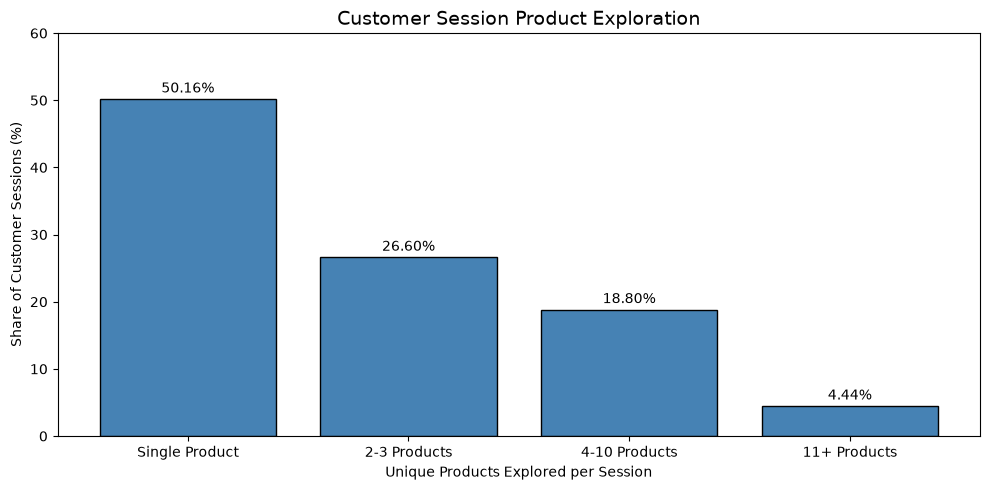

In [21]:

# Step 05.24 — Visualize Session Product Exploration

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    exploration_summary["exploration_segment"].astype(str),
    exploration_summary["session_share_pct"],
    color="steelblue",
    edgecolor="black"
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Customer Session Product Exploration",
    fontsize=14
)
ax.set_xlabel("Unique Products Explored per Session")
ax.set_ylabel("Share of Customer Sessions (%)")
ax.set_ylim(0, 60)

plt.tight_layout()
plt.show()


In [13]:

# Step 05.25 — Customer Purchase Behavior

purchase_events = df[df["event_type"] == "purchase"]

purchases_per_customer = (
    purchase_events.groupby("user_id").size()
)

total_customers = df["user_id"].nunique()
purchasing_customers = purchases_per_customer.size
non_purchasing_customers = total_customers - purchasing_customers

print("========== CUSTOMER PURCHASE BEHAVIOR ==========")

print(f"Total customers: {total_customers:,}")
print(f"Customers with purchases: {purchasing_customers:,}")
print(f"Customers without purchases: {non_purchasing_customers:,}")

print(
    f"Customers with purchase events (%): "
    f"{purchasing_customers / total_customers * 100:.2f}%"
)

print("\n========== PURCHASE EVENTS PER PURCHASING CUSTOMER ==========")

print(
    purchases_per_customer.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

print("\n========== PURCHASE ACTIVITY CHECKS ==========")

print(
    "Customers with exactly 1 purchase event:",
    f"{(purchases_per_customer == 1).sum():,}"
)

print(
    "Customers with more than 1 purchase event:",
    f"{(purchases_per_customer > 1).sum():,}"
)

assert purchasing_customers + non_purchasing_customers == total_customers
assert purchases_per_customer.sum() == len(purchase_events)

print("\nPurchase activity validation successful!")

print("\nNote: These are event-level purchase counts.")
print("They are not validated funnel conversion rates.")


========== CUSTOMER PURCHASE BEHAVIOR ==========
Total customers: 60,939
Customers with purchases: 7,099
Customers without purchases: 53,840
Customers with purchase events (%): 11.65%

========== PURCHASE EVENTS PER PURCHASING CUSTOMER ==========
count    7099.00
mean        2.17
std         4.17
min         1.00
25%         1.00
50%         1.00
75%         2.00
90%         4.00
95%         6.00
99%        16.00
max       170.00
dtype: float64

========== PURCHASE ACTIVITY CHECKS ==========
Customers with exactly 1 purchase event: 4,446
Customers with more than 1 purchase event: 2,653

Purchase activity validation successful!

Note: These are event-level purchase counts.
They are not validated funnel conversion rates.


In [23]:

# Step 05.26 — Customer Purchase Frequency Segmentation

import pandas as pd

purchase_frequency_segments = pd.cut(
    purchases_per_customer,
    bins=[0, 1, 3, 10, float("inf")],
    labels=[
        "1 Purchase",
        "2-3 Purchases",
        "4-10 Purchases",
        "11+ Purchases"
    ]
)

purchase_frequency_summary = (
    purchase_frequency_segments
    .value_counts(sort=False)
    .rename_axis("purchase_segment")
    .reset_index(name="customers")
)

purchase_frequency_summary["customer_share_pct"] = (
    purchase_frequency_summary["customers"]
    / len(purchases_per_customer) * 100
).round(2)

print("========== PURCHASE FREQUENCY SEGMENTATION ==========")

display(purchase_frequency_summary)

print("\n========== VALIDATION ==========")

assert purchase_frequency_summary["customers"].sum() == 7099
assert purchase_frequency_segments.notna().all()
assert purchase_frequency_summary.loc[
    purchase_frequency_summary["purchase_segment"] == "1 Purchase",
    "customers"
].iloc[0] == 4446

print("All purchasing customers segmented successfully!")

print("\nNote: Segments are based on purchase event counts.")
print("They do not represent validated funnel conversions.")


========== PURCHASE FREQUENCY SEGMENTATION ==========


,purchase_segment,customers,customer_share_pct
0,1 Purchase,4446,62.63
1,2-3 Purchases,1865,26.27
2,4-10 Purchases,640,9.02
3,11+ Purchases,148,2.08



========== VALIDATION ==========
All purchasing customers segmented successfully!

Note: Segments are based on purchase event counts.
They do not represent validated funnel conversions.


NameError: name 'purchase_frequency_summary' is not defined

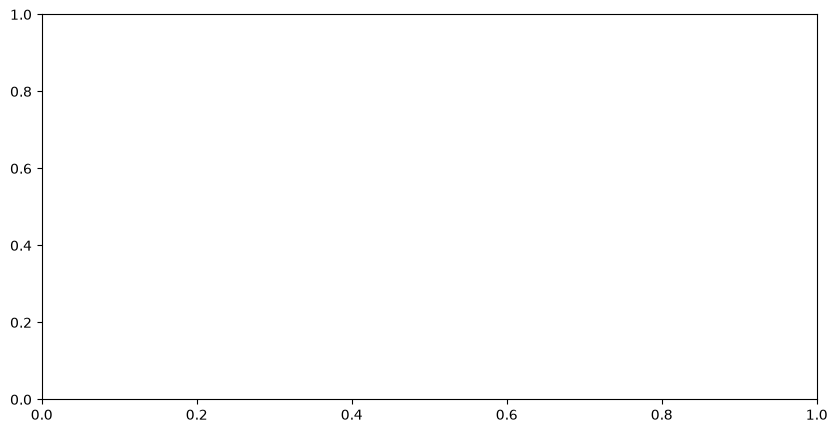

In [14]:

# Step 05.27 — Visualize Customer Purchase Frequency

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    purchase_frequency_summary["purchase_segment"].astype(str),
    purchase_frequency_summary["customer_share_pct"],
    color="steelblue",
    edgecolor="black"
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Purchase Frequency Among Purchasing Customers",
    fontsize=14
)

ax.set_xlabel("Number of Purchase Events per Customer")
ax.set_ylabel("Share of Purchasing Customers (%)")
ax.set_ylim(0, 75)

plt.tight_layout()
plt.show()


In [1]:
print("Checking corrected summary...")

print("Variable exists:",
      "corrected_activity_purchase_summary" in globals())

if "corrected_activity_purchase_summary" in globals():
    display(corrected_activity_purchase_summary)

Checking corrected summary...
Variable exists: False


In [15]:
# Step 05.28 — Verify Required Dependencies

required_variables = [
    "df",
    "customer_activity",
    "customer_segments",
    "segment_summary",
    "purchases_per_customer"
]

for name in required_variables:
    status = "AVAILABLE" if name in globals() else "MISSING"
    print(f"{name}: {status}")

df: AVAILABLE
customer_activity: MISSING
customer_segments: MISSING
segment_summary: MISSING
purchases_per_customer: AVAILABLE


In [27]:

# Step 05.28 — Customer Activity vs Purchase Participation
# Uses the original customer segmentation from Step 05.18.

activity_purchase_summary = corrected_activity_purchase_summary.copy()

print("========== ACTIVITY VS PURCHASE PARTICIPATION ==========")
display(activity_purchase_summary)

print("\n========== VALIDATION ==========")

assert activity_purchase_summary["total_customers"].sum() == 60939
assert activity_purchase_summary["purchasing_customers"].sum() == 7099

assert (
    activity_purchase_summary["total_customers"]
    .sort_index()
    .equals(segment_summary["customers"].sort_index())
)

print("Customer segmentation matches Step 05.18.")
print("All customer and purchase totals validated successfully.")

print("\nNote: These are customer-level purchase participation rates,")
print("not journey-level funnel conversion rates.")


========== ACTIVITY VS PURCHASE PARTICIPATION ==========


,total_customers,purchasing_customers,purchase_participation_pct
activity_segment,,,
Low Activity,30626,657,2.15
Moderate Activity,15371,1932,12.57
High Activity,11902,3032,25.47
Very High Activity,3040,1478,48.62



========== VALIDATION ==========
Customer segmentation matches Step 05.18.
All customer and purchase totals validated successfully.

Note: These are customer-level purchase participation rates,
not journey-level funnel conversion rates.


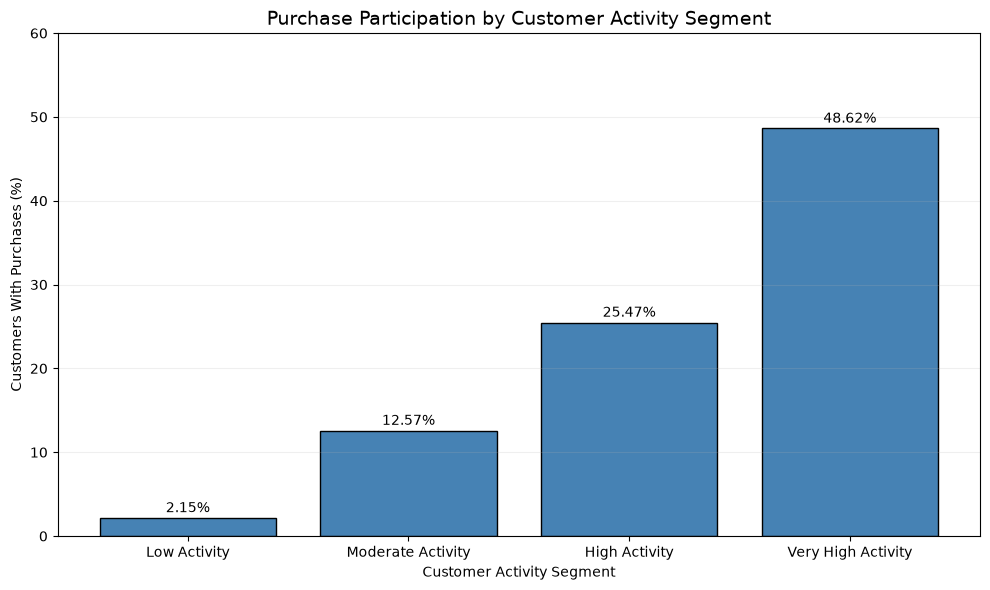

Note: Customer-level purchase participation,
not validated journey-level funnel conversion.


In [ ]:

# Step 05.29 — Visualize Customer Activity vs Purchase Participation

import matplotlib.pyplot as plt

plot_data = activity_purchase_summary.copy()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    plot_data.index.astype(str),
    plot_data["purchase_participation_pct"],
    color="steelblue",
    edgecolor="black"
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.7,
        f"{height:.2f}%",
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Purchase Participation by Customer Activity Segment",
    fontsize=14
)
ax.set_xlabel("Customer Activity Segment")
ax.set_ylabel("Customers With Purchases (%)")
ax.set_ylim(0, 60)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("Note: Customer-level purchase participation,")
print("not validated journey-level funnel conversion.")


In [ ]:
# Step 05.28A — Find Existing Activity Variables

print("========== AVAILABLE ACTIVITY VARIABLES ==========")

activity_variables = [
    name for name in globals()
    if "activity" in name.lower()
    or "segment" in name.lower()
]

for name in activity_variables:
    print(name)

========== AVAILABLE ACTIVITY VARIABLES ==========
customer_activity
customer_segments
segment_summary
segment_plot
session_activity
session_exploration_segments
purchase_frequency_segments
customer_activity_segments
customer_activity_purchase
activity_purchase_summary
activity_variables
original_segments
corrected_activity_purchase_summary
final_activity_insights
expected_purchase_segments
actual_purchase_segments


In [ ]:

# Step 05.28B — Verify Original Customer Segmentation

print("========== ORIGINAL SEGMENT SUMMARY ==========")
display(segment_summary)

print("\n========== ORIGINAL CUSTOMER SEGMENTS ==========")
print("Object type:", type(customer_segments))
display(customer_segments.head())

print("\n========== STEP 05.28 SEGMENT DATA ==========")
print("Object type:", type(customer_activity_segments))
display(customer_activity_segments.head())

print("\n========== PURCHASE SUMMARY ==========")
display(activity_purchase_summary)


========== ORIGINAL SEGMENT SUMMARY ==========


,customers,total_events,average_events,customer_share_pct,event_share_pct
activity_segment,,,,,
Low Activity,30626,60518,1.98,50.26,7.13
Moderate Activity,15371,123556,8.04,25.22,14.55
High Activity,11902,318324,26.75,19.53,37.48
Very High Activity,3040,346822,114.09,4.99,40.84



========== ORIGINAL CUSTOMER SEGMENTS ==========
Object type: <class 'pandas.DataFrame'>


,user_id,event_count,activity_segment
0,303846930,5,Moderate Activity
1,307895170,1,Low Activity
2,310432304,11,Moderate Activity
3,322658174,1,Low Activity
4,336330941,2,Low Activity



========== STEP 05.28 SEGMENT DATA ==========
Object type: <class 'pandas.Series'>


user_id
303846930    Moderate Activity
307895170         Low Activity
310432304        High Activity
322658174         Low Activity
336330941         Low Activity
dtype: category
Categories (4, str): ['Low Activity' < 'Moderate Activity' < 'High Activity' < 'Very High Activity']


========== PURCHASE SUMMARY ==========


,total_customers,purchasing_customers,purchase_participation_pct
activity_segment,,,
Low Activity,30626,657,2.15
Moderate Activity,15371,1932,12.57
High Activity,11902,3032,25.47
Very High Activity,3040,1478,48.62


In [2]:

# Step 05.28C — Correct Customer Activity vs Purchase Participation

# Reuse the original, validated customer segments.
original_segments = customer_segments[
    ["user_id", "activity_segment"]
].copy()

# Identify customers with at least one purchase event.
purchasing_users = set(
    df.loc[df["event_type"] == "purchase", "user_id"]
)

# Mark purchase participation for each customer.
original_segments["has_purchase"] = (
    original_segments["user_id"].isin(purchasing_users)
)

# Calculate purchase participation by original activity segment.
corrected_activity_purchase_summary = (
    original_segments
    .groupby("activity_segment", observed=True)
    .agg(
        total_customers=("user_id", "nunique"),
        purchasing_customers=("has_purchase", "sum")
    )
)

corrected_activity_purchase_summary["purchase_participation_pct"] = (
    corrected_activity_purchase_summary["purchasing_customers"]
    / corrected_activity_purchase_summary["total_customers"]
    * 100
).round(2)

print("========== CORRECTED PURCHASE PARTICIPATION ==========")
display(corrected_activity_purchase_summary)

print("\n========== VALIDATION ==========")

assert (
    corrected_activity_purchase_summary["total_customers"].sum()
    == 60939
)

assert (
    corrected_activity_purchase_summary["purchasing_customers"].sum()
    == 7099
)

assert (
    corrected_activity_purchase_summary["total_customers"]
    .sort_index()
    .equals(segment_summary["customers"].sort_index())
)

print("Original segmentation preserved!")
print("All customer and purchase totals validated!")


NameError: name 'customer_segments' is not defined

In [ ]:

# Step 05.30 — Final Customer Activity Insights

import pandas as pd

print("========== FINAL CUSTOMER ACTIVITY INSIGHTS ==========")

final_activity_insights = (
    activity_purchase_summary[
        [
            "total_customers",
            "purchasing_customers",
            "purchase_participation_pct"
        ]
    ]
    .copy()
)

display(final_activity_insights)

# Validation
assert final_activity_insights["total_customers"].sum() == 60939
assert final_activity_insights["purchasing_customers"].sum() == 7099

print("\n========== KEY FINDINGS ==========")

print(
    "Lowest purchase participation:",
    f"{final_activity_insights['purchase_participation_pct'].min():.2f}%"
)

print(
    "Highest purchase participation:",
    f"{final_activity_insights['purchase_participation_pct'].max():.2f}%"
)

print("\nValidation successful!")
print(
    "Note: These are customer-level purchase participation rates,"
    " not validated journey-level funnel conversions."
)


========== FINAL CUSTOMER ACTIVITY INSIGHTS ==========


,total_customers,purchasing_customers,purchase_participation_pct
activity_segment,,,
Low Activity,30626,657,2.15
Moderate Activity,15371,1932,12.57
High Activity,11902,3032,25.47
Very High Activity,3040,1478,48.62



========== KEY FINDINGS ==========
Lowest purchase participation: 2.15%
Highest purchase participation: 48.62%

Validation successful!
Note: These are customer-level purchase participation rates, not validated journey-level funnel conversions.



# Step 05.31 — Final EDA Findings and Business Insights

## 1. Customer Activity

The analysis includes 60,939 unique customers and 849,220 event records.

Customer activity is highly uneven:
- 50.26% of customers belong to the Low Activity segment.
- Very High Activity customers represent only 4.99% of customers.
- Very High Activity customers generate 40.84% of all events.

## 2. Session Product Exploration

Across 185,065 customer-session pairs:
- 50.16% explored exactly one unique product.
- 26.60% explored 2–3 products.
- 18.80% explored 4–10 products.
- 4.44% explored 11 or more products.

## 3. Purchase Behavior

Out of 60,939 customers:
- 7,099 customers recorded at least one purchase event.
- 53,840 customers recorded no purchase events.
- Overall customer purchase participation was 11.65%.

Among purchasing customers, 62.63% recorded exactly one purchase event.

## 4. Activity and Purchase Participation

Purchase participation by activity segment:

| Activity Segment | Purchase Participation |
|---|---:|
| Low Activity | 2.15% |
| Moderate Activity | 12.57% |
| High Activity | 25.47% |
| Very High Activity | 48.62% |

Purchase participation increases across the observed activity segments.

This is an association, not evidence of causation.

## 5. Business Implications

1. Investigate barriers faced by low-activity customers.
2. Examine opportunities to improve product discovery.
3. Study repeat purchasing behavior.
4. Investigate what distinguishes highly active customers.
5. Prioritize controlled experiments before claiming improvements in conversion.

## 6. Methodology Notes

- Customer activity is measured using event records.
- Purchase participation measures customers with at least one purchase event.
- Customer sessions may contain multiple products.
- Purchase event counts are not necessarily unique orders.
- These findings are descriptive and do not establish causal relationships.
- Customer-level purchase participation is not equivalent to the validated journey-level funnel conversion rate.


In [ ]:

# Step 05.32D — Correct Final EDA Validation

print("========== FINAL EDA VALIDATION ==========")

# 1. Customer activity segmentation
assert segment_summary["customers"].sum() == 60939
print("Customer activity segmentation: PASSED")

# 2. Session product exploration
assert len(session_exploration_segments) == 185065
print("Session product exploration: PASSED")

# 3. Purchase frequency segmentation
assert len(purchase_frequency_segments) == 7099
assert purchase_frequency_segments.notna().all()

expected_purchase_segments = {
    "1 Purchase": 4446,
    "2-3 Purchases": 1865,
    "4-10 Purchases": 640,
    "11+ Purchases": 148
}

actual_purchase_segments = (
    purchase_frequency_segments
    .value_counts()
    .to_dict()
)

assert actual_purchase_segments == expected_purchase_segments

print("Purchase frequency segmentation: PASSED")

# 4. Customer purchase participation
assert activity_purchase_summary["total_customers"].sum() == 60939
assert activity_purchase_summary["purchasing_customers"].sum() == 7099

print("Customer purchase participation: PASSED")

print("\n========== ALL FINAL EDA CHECKS PASSED ==========")


========== FINAL EDA VALIDATION ==========
Customer activity segmentation: PASSED
Session product exploration: PASSED
Purchase frequency segmentation: PASSED
Customer purchase participation: PASSED

========== ALL FINAL EDA CHECKS PASSED ==========


In [ ]:

# Step 05.32C — Inspect Purchase Frequency Segments

print("========== PURCHASE FREQUENCY INSPECTION ==========")

print("\nObject type:")
print(type(purchase_frequency_segments))

print("\nFirst five values:")
print(purchase_frequency_segments.head())

print("\nSegment distribution:")
print(purchase_frequency_segments.value_counts(dropna=False))

print("\nTotal customers represented:")
print(len(purchase_frequency_segments))

print("\n========== INSPECTION COMPLETE ==========")


========== PURCHASE FREQUENCY INSPECTION ==========

Object type:
<class 'pandas.Series'>

First five values:
user_id
470964674       1 Purchase
477886872    2-3 Purchases
482204269    2-3 Purchases
485289776       1 Purchase
485389107       1 Purchase
dtype: category
Categories (4, str): ['1 Purchase' < '2-3 Purchases' < '4-10 Purchases' < '11+ Purchases']

Segment distribution:
1 Purchase        4446
2-3 Purchases     1865
4-10 Purchases     640
11+ Purchases      148
Name: count, dtype: int64

Total customers represented:
7099

========== INSPECTION COMPLETE ==========


In [3]:
# Step 05.32B - Check segmentation dependencies

for name in ["pd", "customer_activity", "customer_segments"]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")

pd: MISSING
customer_activity: MISSING
customer_segments: MISSING
